In [1]:
import numpy as np
import pandas as pd
import torch
import astropy.units as u
from astropy.coordinates import SkyCoord

from dataset import AsteroidDataset
from normalization import AsteroidNormalizer
from model import AsteroidLSTM
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv("data/gaia_asteroids.csv")

asteroids = df["number_mp"].unique()

rng = np.random.default_rng(42)
rng.shuffle(asteroids)

split = int(len(asteroids) * 0.8)

train_ids = asteroids[:split]
val_ids = asteroids[split:]

train_df = df[df["number_mp"].isin(train_ids)]
val_df = df[df["number_mp"].isin(val_ids)]

train_dataset = AsteroidDataset(train_df, seq_len=3)
val_dataset = AsteroidDataset(val_df, seq_len=3)

print("Total train samples:", len(train_dataset))
print("Total val samples:", len(val_dataset))

Total train samples: 283
Total val samples: 57


In [ ]:

from sklearn.preprocessing import RobustScaler

def extract(dataset):
    X = torch.stack([s[0] for s in dataset])
    H = torch.stack([s[1] for s in dataset])
    Y = torch.stack([s[2] for s in dataset])
    return X, H, Y

X_train, H_train, Y_train = extract(train_dataset)
X_val, H_val, Y_val = extract(val_dataset)

normalizer = AsteroidNormalizer()
normalizer.fit(X_train.numpy())

X_train, Y_train = normalizer.transform(
    X_train.numpy(), Y_train.numpy()
)
X_val, Y_val = normalizer.transform(
    X_val.numpy(), Y_val.numpy()
)

time_scaler = RobustScaler(with_centering=False)

time_scaler.fit(X_train[:, 1:, 2].reshape(-1, 1))

X_train[:, :, 2] = time_scaler.transform(
    X_train[:, :, 2].reshape(-1, 1)
).reshape(X_train.shape[0], X_train.shape[1])

X_val[:, :, 2] = time_scaler.transform(
    X_val[:, :, 2].reshape(-1, 1)
).reshape(X_val.shape[0], X_val.shape[1])

H_train = time_scaler.transform(H_train.numpy())
H_val = time_scaler.transform(H_val.numpy())

X_train = torch.tensor(X_train, dtype=torch.float32)
Y_train = torch.tensor(Y_train, dtype=torch.float32)
H_train = torch.tensor(H_train, dtype=torch.float32)

X_val = torch.tensor(X_val, dtype=torch.float32)
Y_val = torch.tensor(Y_val, dtype=torch.float32)
H_val = torch.tensor(H_val, dtype=torch.float32)

print("Normalized X:\n", X_train[0])
print("Normalized horizon:", H_train[0])
print("Normalized Y:", Y_train[0])


Normalized X:
 tensor([[-1.3135, -1.7410,  0.0000],
        [-0.3890, -0.5177,  1.7233],
        [ 0.0000,  0.0000,  0.7254]])
Normalized horizon: tensor([1.7231])
Normalized Y: tensor([0.9236, 1.2383])


In [4]:
print("Time scaler:", time_scaler.scale_)

print("X time range:",
      X_train[:, :, 2].min().item(),
      X_train[:, :, 2].max().item())

print("Horizon range:",
      H_train.min().item(),
      H_train.max().item())

print("Horizon median:",
      H_train.median().item())

print("Y range:",
      Y_train.min().item(),
      Y_train.max().item())

Time scaler: [0.10215663]
X time range: 0.0 14.69312858581543
Horizon range: 0.7230256795883179 14.69312858581543
Horizon median: 1.7232319116592407
Y range: -32.1882209777832 7.9987406730651855


In [5]:
print("Position scaler:", normalizer.scaler.scale_)

Y_degrees = normalizer.inverse_transform(Y_train.numpy())

print("Y percentiles (normalized):")
print(np.percentile(np.abs(Y_train.numpy()), [50, 90, 95, 99, 100]))

print("Y percentiles (degrees):")
print(np.percentile(np.abs(Y_degrees), [50, 90, 95, 99, 100]))

Position scaler: [0.0736933  0.00646585]
Y percentiles (normalized):
[ 0.7278524   3.3226254   4.17887259  6.35170133 32.18822098]
Y percentiles (degrees):
[0.01870312 0.06803467 0.08602747 0.1223079  0.58945358]


Epoch 10 | Train: 0.599552 | Val: 0.389050
Epoch 20 | Train: 0.456592 | Val: 0.292235
Epoch 30 | Train: 0.379477 | Val: 0.249802
Epoch 40 | Train: 0.337591 | Val: 0.218550
Epoch 50 | Train: 0.295015 | Val: 0.188810
Epoch 60 | Train: 0.262645 | Val: 0.167905
Epoch 70 | Train: 0.235195 | Val: 0.145438
Epoch 80 | Train: 0.215443 | Val: 0.123237
Epoch 90 | Train: 0.196298 | Val: 0.110405
Epoch 100 | Train: 0.176801 | Val: 0.099896
Epoch 110 | Train: 0.177075 | Val: 0.088198
Epoch 120 | Train: 0.168295 | Val: 0.081825
Epoch 130 | Train: 0.150630 | Val: 0.074579
Epoch 140 | Train: 0.146064 | Val: 0.069001
Epoch 150 | Train: 0.140779 | Val: 0.064407
Epoch 160 | Train: 0.126755 | Val: 0.059583
Epoch 170 | Train: 0.136685 | Val: 0.055776
Epoch 180 | Train: 0.121554 | Val: 0.052387
Epoch 190 | Train: 0.132538 | Val: 0.050896
Epoch 200 | Train: 0.106914 | Val: 0.047847
Epoch 210 | Train: 0.123321 | Val: 0.050779
Epoch 220 | Train: 0.118836 | Val: 0.044191
Epoch 230 | Train: 0.106600 | Val: 0.0393

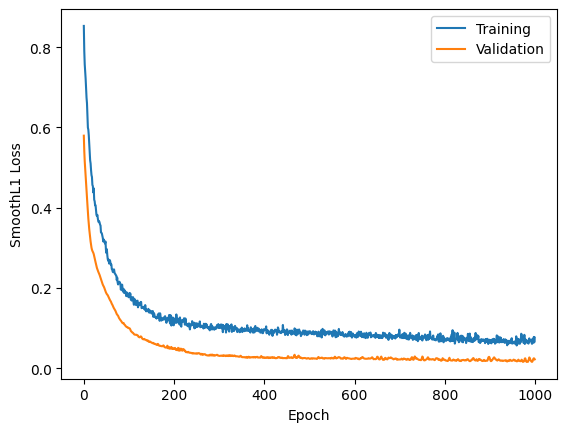

In [6]:
model = AsteroidLSTM(input_size=3, hidden_size=64)

criterion = torch.nn.SmoothL1Loss(beta=1.0)
optimizer = torch.optim.AdamW(model.parameters(), lr=0.001)

epochs = 1000
train_losses = []
val_losses = []

for epoch in range(epochs):
    # Train
    model.train()

    # Forward pass
    Y_pred = model(X_train, H_train)

    # Calculate loss
    loss = criterion(Y_pred, Y_train)

    # Backpropagation
    optimizer.zero_grad()
    loss.backward()

    torch.nn.utils.clip_grad_norm_(
        model.parameters(),
        max_norm=1.0
    )

    optimizer.step()

    train_losses.append(loss.item())

    # Val
    model.eval()

    with torch.no_grad():
        val_pred = model(X_val, H_val)
        val_loss = criterion(val_pred, Y_val)

    val_losses.append(val_loss.item())

    if (epoch + 1) % 10 == 0:
        print(
            f"Epoch {epoch+1} | "
            f"Train: {loss.item():.6f} | "
            f"Val: {val_loss.item():.6f}"
        )

plt.plot(train_losses, label="Training")
plt.plot(val_losses, label="Validation")
plt.xlabel("Epoch")
plt.ylabel("SmoothL1 Loss")
plt.legend()
plt.show()


In [8]:

model.eval()

with torch.no_grad():
    val_pred = model(X_val, H_val).cpu().numpy()

pred = normalizer.inverse_transform(val_pred)
actual = normalizer.inverse_transform(Y_val.cpu().numpy())

errors = []

for i, reference in enumerate(val_dataset.references):
    frame = reference.skyoffset_frame()

    p = SkyCoord(
        lon=pred[i, 0] * u.deg,
        lat=pred[i, 1] * u.deg,
        frame=frame
    )

    a = SkyCoord(
        lon=actual[i, 0] * u.deg,
        lat=actual[i, 1] * u.deg,
        frame=frame
    )

    errors.append(p.separation(a).arcsec)

errors = np.array(errors)

print("Mean error:", errors.mean(), "arcsec")
print("Median error:", np.median(errors), "arcsec")
print("90th percentile:", np.percentile(errors, 90), "arcsec")

Mean error: 17.284422432518312 arcsec
Median error: 9.110714540745864 arcsec
90th percentile: 38.20714312984809 arcsec


In [10]:
import torch
from pathlib import Path

Path("export").mkdir(exist_ok=True)

model.eval().cpu()

dummy_X = torch.randn(1, 3, 3)
dummy_H = torch.randn(1, 1)

torch.onnx.export(
    model,
    (dummy_X, dummy_H),
    "export/asteroid_lstm.onnx",
    input_names=["observations", "horizon"],
    output_names=["predicted_displacement"],
    dynamic_axes={
        "observations": {0: "batch_size"},
        "horizon": {0: "batch_size"},
        "predicted_displacement": {0: "batch_size"}
    },
    opset_version=17,
    dynamo=False
)

print("Modelo ONNX exportado")

C:\Users\Ayuu\AppData\Local\Temp\ipykernel_16232\807577125.py:11: DeprecationWarning: You are using the legacy TorchScript-based ONNX export. Starting in PyTorch 2.9, the new torch.export-based ONNX exporter has become the default. Learn more about the new export logic: https://docs.pytorch.org/docs/stable/onnx_export.html. For exporting control flow: https://pytorch.org/tutorials/beginner/onnx/export_control_flow_model_to_onnx_tutorial.html
  torch.onnx.export(


Modelo ONNX exportado


In [11]:
import json

config = {
    "position_scale": normalizer.scaler.scale_.tolist(),
    "time_scale": float(time_scaler.scale_[0]),
    "seq_len": 3
}

with open("export/preprocessing.json", "w") as f:
    json.dump(config, f, indent=2)

In [ ]:
import torch
import numpy as np
import onnxruntime as ort

x = X_val[:5].cpu().numpy()
h = H_val[:5].cpu().numpy()

model.eval()

with torch.no_grad():
    pred_torch = model(
        torch.from_numpy(x),
        torch.from_numpy(h)
    ).cpu().numpy()

session = ort.InferenceSession(
    "export/asteroid_lstm.onnx"
)

pred_onnx = session.run(
    ["predicted_displacement"],
    {
        "observations": x,
        "horizon": h
    }
)[0]

print("PyTorch:\n", pred_torch)
print("\nONNX:\n", pred_onnx)

max_error = np.max(np.abs(pred_torch - pred_onnx))
print(f"\nMaximum difference: {max_error:.10f}")

np.testing.assert_allclose(
    pred_torch,
    pred_onnx,
    rtol=1e-4,
    atol=1e-4
)

print("PASS: ONNX and PyTorch produce equivalent results")

PyTorch:
 [[-0.04602106  0.1754586 ]
 [ 0.33933908 -0.17102218]
 [ 0.74086285 -0.32569078]
 [ 0.35397604 -0.10088766]
 [ 1.1567538  -0.14335616]]

ONNX:
 [[-0.04602101  0.1754585 ]
 [ 0.33933902 -0.1710222 ]
 [ 0.7408631  -0.32569122]
 [ 0.353976   -0.10088778]
 [ 1.156754   -0.143356  ]]

Maximum difference: 0.0000004470
PASS: ONNX and PyTorch produce equivalent results
